# LightGBM for Small-Cap Bankruptcy Prediction in the United States

**Individual AP Research project by Aarav Singhvi.**

[Read the paper](paper/AP-Research-Final-Paper.pdf) · [Project README](README.md)

This is a presentation copy of the original research notebook. Its saved model results correspond to the experiment discussed in the paper: **95.3% accuracy, 60% recall, and 11.6% precision** for the tuned model. The study intentionally prioritized recall; the precision tradeoff remains important context.

**Historical workflow:** the saved results have not been independently reproduced. SMOTE is applied before cross-validation, rows are not chronologically ordered for the validation splitter, and feature/cohort exploration uses the full data. Saved cells were executed out of order, and some printed metric names differ from the source. These limitations are retained and disclosed, rather than silently rewriting the experiment behind the paper.

The separate `validation_revision.ipynb` and `train.py` implement a later evaluation extension. Its changed cohort, features, transformations, and average-precision objective must not be confused with the original recall-focused study.

## Run the historical notebook

Install `requirements.txt` and JupyterLab, put the Kaggle CSV at `data/american_bankruptcy.csv`, and run cells from the repository root. The local file path was made portable; local warning paths were removed from saved outputs, and the optional failed Graphviz plot was omitted. Existing saved result figures are retained. Rerunning may differ from the saved results because the original Optuna sampler was not seeded.


## 1. Load the financial data


In [2]:
#import libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import lightgbm as lgb
from lightgbm import LGBMRegressor
import sklearn
from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score, RandomizedSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, auc, roc_curve, ConfusionMatrixDisplay
import optuna
from imblearn.over_sampling import SMOTE

In [3]:
from pathlib import Path
file_path = Path("data/american_bankruptcy.csv")
df = pd.read_csv(file_path)


In [4]:
df.head()


,company_name,status_label,year,X1,X2,X3,X4,X5,X6,X7,...,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18
0,C_1,alive,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,...,1024.333,740.998,180.447,70.658,191.226,163.816,201.026,1024.333,401.483,935.302
1,C_1,alive,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,...,874.255,701.854,179.987,45.790,160.444,125.392,204.065,874.255,361.642,809.888
2,C_1,alive,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,...,638.721,710.199,217.699,4.711,112.244,150.464,139.603,638.721,399.964,611.514
3,C_1,alive,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,...,606.337,686.621,164.658,3.573,109.590,203.575,124.106,606.337,391.633,575.592
4,C_1,alive,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,...,651.958,709.292,248.666,20.811,128.656,131.261,131.884,651.958,407.608,604.467


## 2. Explore labels and select the original company cohort


In [5]:
#replace status w/ 0,1
df['status_label'] = df['status_label'].map({'failed': 1, 'alive': 0})
df.head()

,company_name,status_label,year,X1,X2,X3,X4,X5,X6,X7,...,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18
0,C_1,0,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,...,1024.333,740.998,180.447,70.658,191.226,163.816,201.026,1024.333,401.483,935.302
1,C_1,0,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,...,874.255,701.854,179.987,45.790,160.444,125.392,204.065,874.255,361.642,809.888
2,C_1,0,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,...,638.721,710.199,217.699,4.711,112.244,150.464,139.603,638.721,399.964,611.514
3,C_1,0,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,...,606.337,686.621,164.658,3.573,109.590,203.575,124.106,606.337,391.633,575.592
4,C_1,0,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,...,651.958,709.292,248.666,20.811,128.656,131.261,131.884,651.958,407.608,604.467


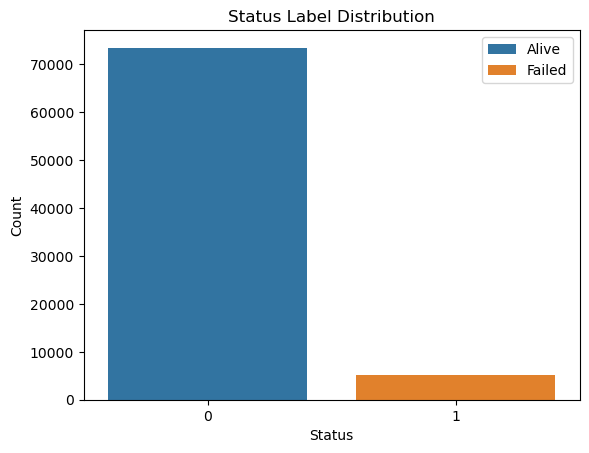

In [6]:
sns.countplot(data = df, x = 'status_label', hue = 'status_label')
plt.title("Status Label Distribution")
plt.xlabel("Status")
plt.ylabel("Count")
plt.legend(labels = ['Alive', 'Failed'])
plt.show()

In [7]:
#identify and filter for small cap companies
company_median_cap = df.groupby('company_name')['X8'].median()
small_cap_companies = company_median_cap[(company_median_cap > 250) & (company_median_cap < 2000)].index
small_cap_df = df[df['company_name'].isin(small_cap_companies)]
print(small_cap_df.shape)
print(small_cap_df['company_name'].nunique())
small_cap_df = small_cap_df.reset_index(drop=True)

(24228, 21)
2474


In [8]:
#check for missing and infinite data
is_missing = small_cap_df.isnull()
print("Are there any missing values? " + str(is_missing.any().any()))
is_infinite = small_cap_df.isin([np.inf, -np.inf])
print("Are there any inf values? " + str(is_infinite.any().any()))

Are there any missing values? False
Are there any inf values? False


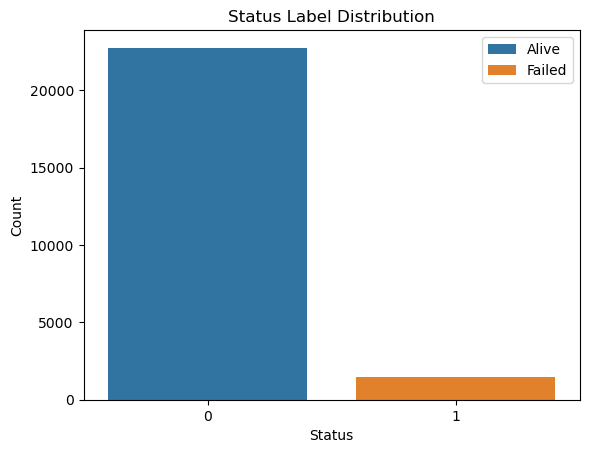

In [9]:
#visualization for class imbalance
sns.countplot(data = small_cap_df, x = 'status_label', hue = 'status_label')
plt.title("Status Label Distribution")
plt.xlabel("Status")
plt.ylabel("Count")
plt.legend(labels = ['Alive', 'Failed'])
plt.show()



## 3. Explore correlations and feature importance


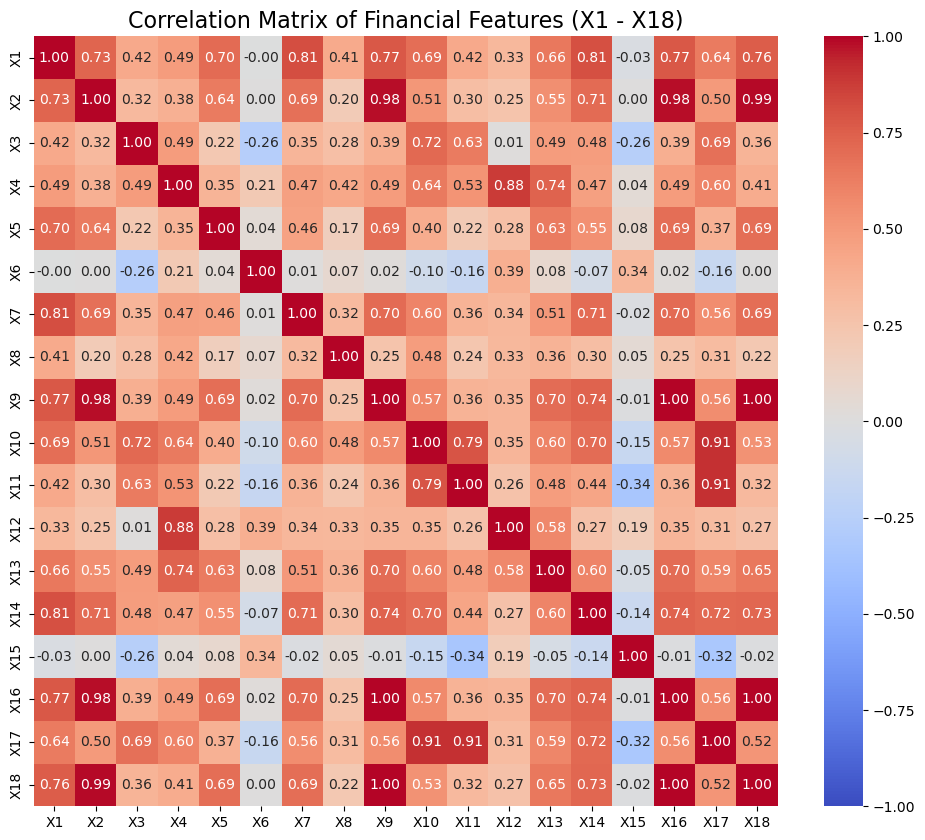

In [10]:
#define subset of features and visualize correlation
features = small_cap_df.columns[3:].tolist()
plt.figure(figsize=(12, 10))
sns.heatmap(small_cap_df[features].corr(), annot=True, cmap='coolwarm', vmin = -1, vmax = 1, fmt=".2f")
plt.title("Correlation Matrix of Financial Features (X1 - X18)", fontsize=16)
plt.show()


In [11]:
#build baseline lightgbm to measure feature importance
X = small_cap_df[features]
y = small_cap_df['status_label']

model = lgb.LGBMClassifier(class_weight = 'balanced', importance_type = 'gain', random_state = 42)
model.fit(X,y)


[LightGBM] [Info] Number of positive: 1470, number of negative: 22758
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001020 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4590
[LightGBM] [Info] Number of data points in the train set: 24228, number of used features: 18
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,'balanced'
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


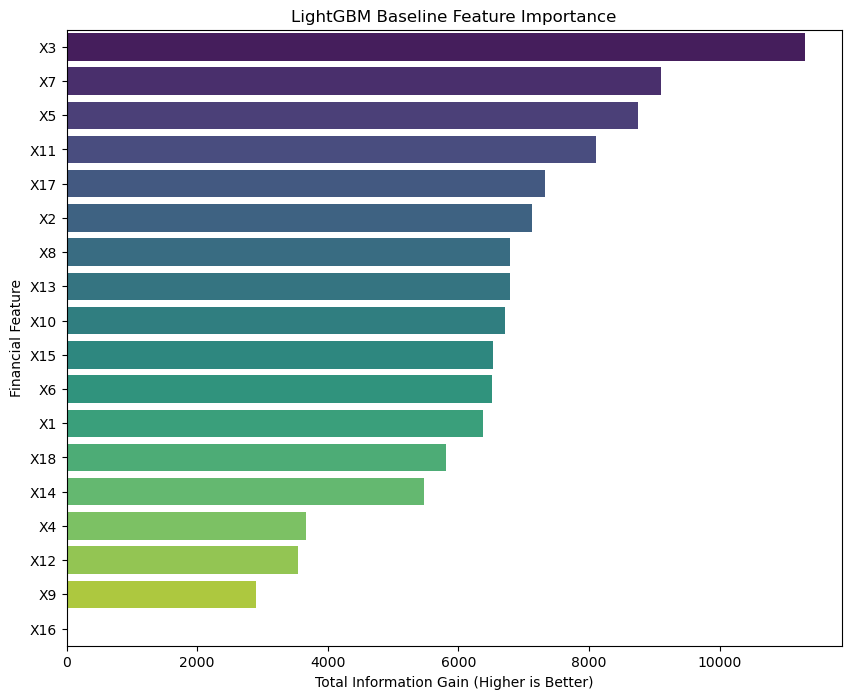

In [12]:
#create feature importance df and visualization 
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': model.feature_importances_
})

importance_df = importance_df.sort_values(by='Importance', ascending = False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title('LightGBM Baseline Feature Importance')
plt.xlabel('Total Information Gain (Higher is Better)')
plt.ylabel('Financial Feature')
plt.show()


In [13]:
#dropping useless columns
if 'X16' in small_cap_df.columns:
    small_cap_df = small_cap_df.drop(['X4', 'X9', 'X10', 'X11', 'X16', 'X18'], axis=1)
small_cap_df.tail()

,company_name,status_label,year,X1,X2,X3,X5,X6,X7,X8,X12,X13,X14,X15,X17
24223,C_8971,0,2014,233.211,43.338,14.094,3.376,25.261,22.846,756.4827,31.521,60.885,28.197,28.095,225.887
24224,C_8971,0,2015,105.559,59.184,42.592,2.288,129.688,54.611,527.5750,159.541,231.969,88.128,157.783,880.327
24225,C_8971,0,2016,63.971,69.074,65.057,2.581,-1.442,42.467,578.8868,13.994,100.784,85.765,156.341,770.233
24226,C_8971,0,2017,135.207,66.527,65.330,2.013,-20.401,27.217,412.6241,3.841,95.357,82.010,135.941,776.697
24227,C_8971,0,2018,82.589,68.817,65.201,2.112,-50.946,45.839,354.1786,2.061,91.696,79.365,84.995,712.687


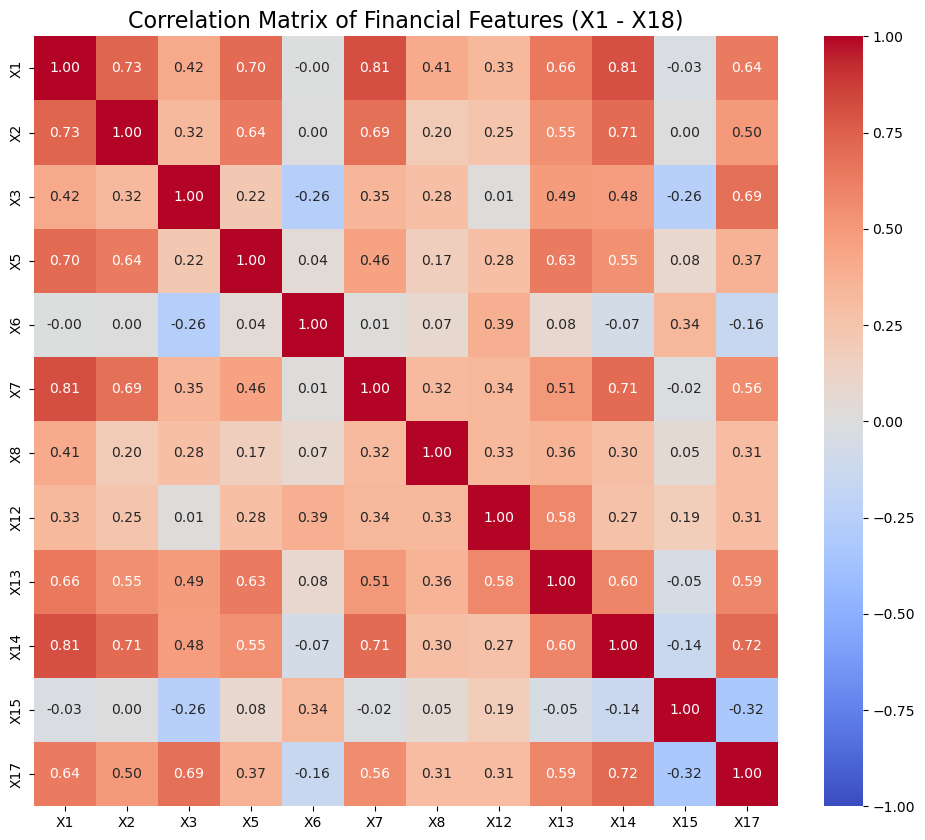

In [14]:
features = small_cap_df.columns[3:].tolist()

plt.figure(figsize=(12, 10))
sns.heatmap(small_cap_df[features].corr(), annot=True, cmap='coolwarm', vmin = -1, vmax = 1, fmt=".2f")
plt.title("Correlation Matrix of Financial Features (X1 - X18)", fontsize=16)
plt.show()

In [15]:
X = small_cap_df[features]
y = small_cap_df['status_label']

model = lgb.LGBMClassifier(class_weight = 'balanced', importance_type = 'gain', random_state = 42)
model.fit(X,y)



[LightGBM] [Info] Number of positive: 1470, number of negative: 22758
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000726 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3060
[LightGBM] [Info] Number of data points in the train set: 24228, number of used features: 12
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,'balanced'
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


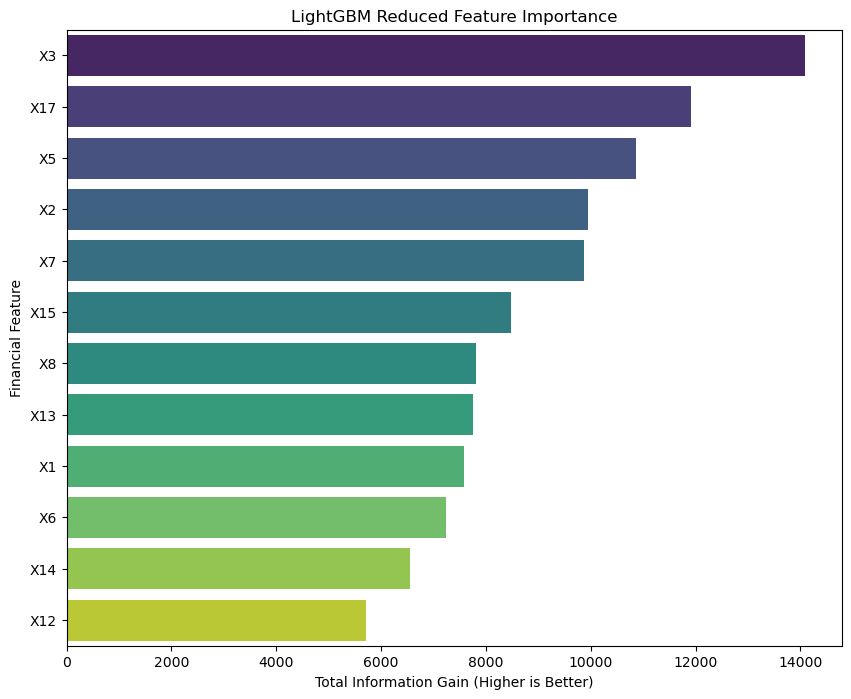

In [16]:
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': model.feature_importances_
})

importance_df = importance_df.sort_values(by='Importance', ascending = False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title('LightGBM Reduced Feature Importance')
plt.xlabel('Total Information Gain (Higher is Better)')
plt.ylabel('Financial Feature')
plt.show()

## 4. Construct the terminal-record target


In [17]:
#sort by year to ensure chronological order. change last row for the failed companies to 1 and preceding rows to 0
last_row_indices = small_cap_df.groupby('company_name').tail(1).index
is_last_row = small_cap_df.index.isin(last_row_indices)
small_cap_df['updated_label'] = (is_last_row & (small_cap_df['status_label'] == 1)).astype(int)
print(small_cap_df['updated_label'].value_counts())



updated_label
0    24076
1      152
Name: count, dtype: int64


In [18]:
#adjust location of updated_label column
if 'status_label' in small_cap_df.columns:
    small_cap_df = small_cap_df.drop('status_label', axis = 1)
col = small_cap_df.pop('updated_label')
small_cap_df.insert(1, 'updated_label', col)
small_cap_df.tail()

,company_name,updated_label,year,X1,X2,X3,X5,X6,X7,X8,X12,X13,X14,X15,X17
24223,C_8971,0,2014,233.211,43.338,14.094,3.376,25.261,22.846,756.4827,31.521,60.885,28.197,28.095,225.887
24224,C_8971,0,2015,105.559,59.184,42.592,2.288,129.688,54.611,527.5750,159.541,231.969,88.128,157.783,880.327
24225,C_8971,0,2016,63.971,69.074,65.057,2.581,-1.442,42.467,578.8868,13.994,100.784,85.765,156.341,770.233
24226,C_8971,0,2017,135.207,66.527,65.330,2.013,-20.401,27.217,412.6241,3.841,95.357,82.010,135.941,776.697
24227,C_8971,0,2018,82.589,68.817,65.201,2.112,-50.946,45.839,354.1786,2.061,91.696,79.365,84.995,712.687


## 5. Split years and oversample the training data


In [19]:
#split training and testing data
train_df = small_cap_df[small_cap_df['year']<=2015]
test_df = small_cap_df[small_cap_df['year']>2015]

X_train = train_df[features]
y_train = train_df['updated_label']

X_test = test_df[features]
y_test = test_df['updated_label']

sm = SMOTE(random_state=42)
X_train, y_train = sm.fit_resample(X_train, y_train)

In [34]:
print(y_train.value_counts())
print(y_test.value_counts())
y_train.head()

updated_label
0    20941
1    20941
Name: count, dtype: int64
updated_label
0    3135
1      30
Name: count, dtype: int64


0    0
1    0
2    0
3    0
4    0
Name: updated_label, dtype: int64

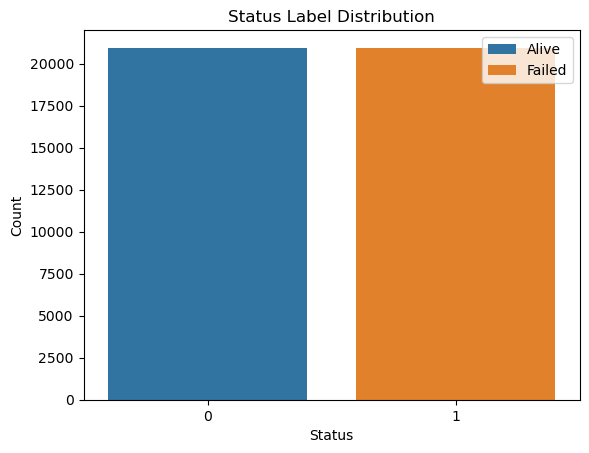

In [35]:
sns.countplot(x = y_train, hue = y_train)
plt.title("Status Label Distribution")
plt.xlabel("Status")
plt.ylabel("Count")
plt.legend(labels = ['Alive', 'Failed'])
plt.show()

## 6. Fit the historical baseline


In [ ]:
#initialize train and test baseline model
lgbm_model = lgb.LGBMClassifier(class_weight='balanced', random_state=42, n_jobs=-1, verbose=-1)

tscv = TimeSeriesSplit(n_splits=5)

cv_scores = cross_val_score(lgbm_model, X_train, y_train, cv=tscv, scoring='recall')

print(f"CV Recall (Class 1): {np.round(cv_scores, 3)}")
print(f"Average Recall: {cv_scores.mean():.3f}\n")

print("Training final model on all 1999-2015 data...")
lgbm_model.fit(X_train, y_train)

print("Testing final model on unseen 2015-2018 data...")
y_pred = lgbm_model.predict(X_test)

print("\n--- FINAL TEST SET REPORT (2016-2018) ---")
print(classification_report(y_test, y_pred))

CV F1-Scores (Class 1): [0.121 0.098 0.651 0.993 0.993]
Average F1-Score: 0.571

Training final model on all 1999-2015 data...
Testing final model on unseen 2015-2018 data...

--- FINAL TEST SET REPORT (2016-2018) ---
              precision    recall  f1-score   support

           0       1.00      0.97      0.98      3135
           1       0.14      0.50      0.22        30

    accuracy                           0.97      3165
   macro avg       0.57      0.74      0.60      3165
weighted avg       0.99      0.97      0.98      3165



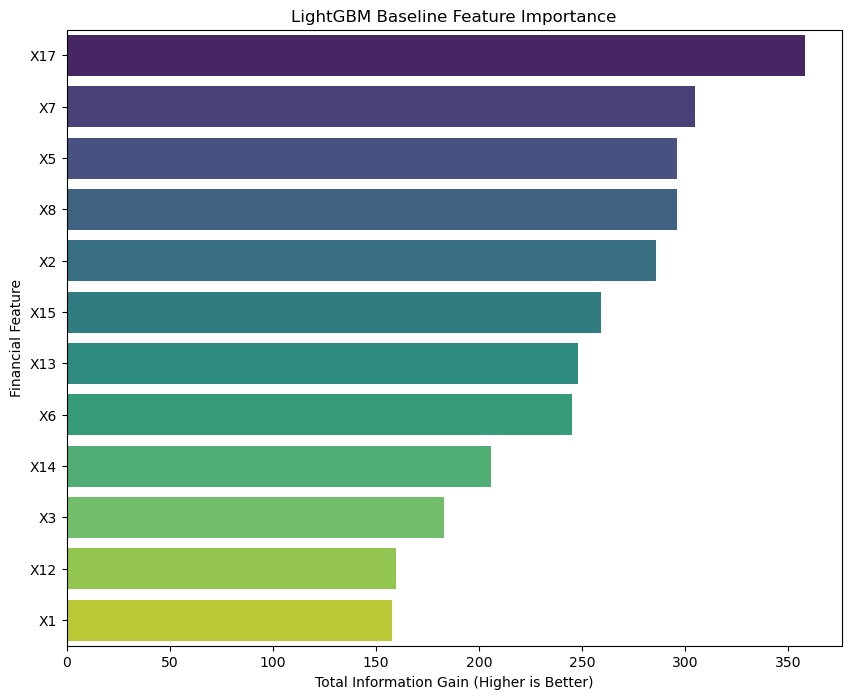

In [23]:
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': lgbm_model.feature_importances_
})

importance_df = importance_df.sort_values(by='Importance', ascending = False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title('LightGBM Baseline Feature Importance')
plt.xlabel('Total Information Gain (Higher is Better)')
plt.ylabel('Financial Feature')
plt.show()

Accuracy Score = 0.9671406003159557
F1 Score = 0.22388059701492538
Recall Score = 0.5
Precision Score = 0.14423076923076922
AUC = 0.7358054226475279


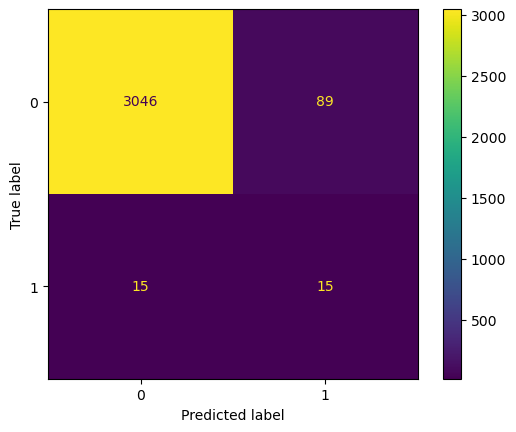

In [24]:
print("Accuracy Score = " + str(accuracy_score(y_test, y_pred)))

print("F1 Score = " + str(f1_score(y_test, y_pred)))

print("Recall Score = " + str(recall_score(y_test, y_pred)))
print("Precision Score = " + str(precision_score(y_test, y_pred)))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

fpr, tpr, thresholds = roc_curve(y_test, y_pred)
print("AUC = " + str(auc(fpr, tpr)))

## 7. Tune the historical model for recall


In [38]:
def objective(trial):
    # Step 2a — define the search space
    params = {
        "n_estimators":      trial.suggest_int("n_estimators", 200, 600),
        "learning_rate":     trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_depth":         trial.suggest_int("max_depth", 5, 10),
        "num_leaves":        trial.suggest_int("num_leaves", 20, 100),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 200),
        "reg_alpha":         trial.suggest_float("reg_alpha", 0.0, 2.0),
        "reg_lambda":        trial.suggest_float("reg_lambda", 0.0, 2.0),
    }

    # Step 2b — build and evaluate the model
    model = lgb.LGBMClassifier(class_weight='balanced', random_state= 42, n_jobs= -1, verbose= -1, **params)
    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=tscv,
        scoring="recall"
    )

    # Step 2c — return the value to minimize
    return cv_scores.mean()

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=30)

print("Best F1:   ", study.best_value)
print("Best params:", study.best_params)

Best F1:    0.7696938168913862
Best params: {'n_estimators': 347, 'learning_rate': 0.013164602980208865, 'max_depth': 5, 'num_leaves': 42, 'min_child_samples': 171, 'reg_alpha': 0.882355216679238, 'reg_lambda': 0.2708559666539688}


## 8. Evaluate the tuned model


In [26]:
best_model = lgb.LGBMClassifier(random_state = 42, class_weight = 'balanced', n_jobs = -1, **study.best_params)
best_model.fit(X_train, y_train)

# Evaluate on test set
y_pred_tuned = best_model.predict(X_test)

from sklearn.metrics import classification_report
print("\n--- TUNED MODEL TEST SET REPORT (2016-2018) ---")
print(classification_report(y_test, y_pred_tuned))


--- TUNED MODEL TEST SET REPORT (2016-2018) ---
              precision    recall  f1-score   support

           0       1.00      0.96      0.98      3135
           1       0.12      0.60      0.19        30

    accuracy                           0.95      3165
   macro avg       0.56      0.78      0.59      3165
weighted avg       0.99      0.95      0.97      3165



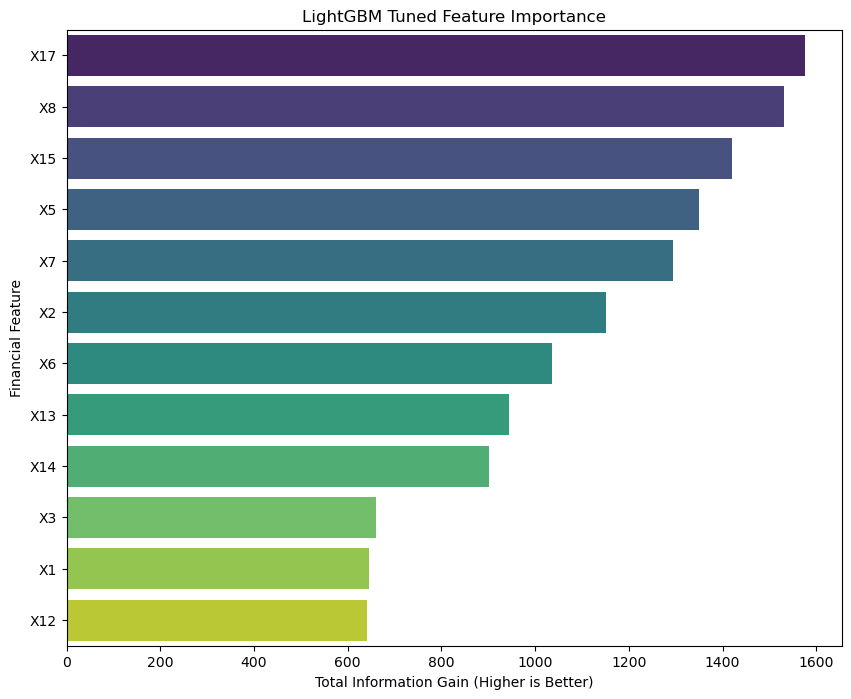

In [27]:
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': best_model.feature_importances_
})

importance_df = importance_df.sort_values(by='Importance', ascending = False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title('LightGBM Tuned Feature Importance')
plt.xlabel('Total Information Gain (Higher is Better)')
plt.ylabel('Financial Feature')
plt.show()

Accuracy Score = 0.9529225908372828
F1 Score = 0.1945945945945946
Recall Score = 0.6
Precision Score = 0.11612903225806452


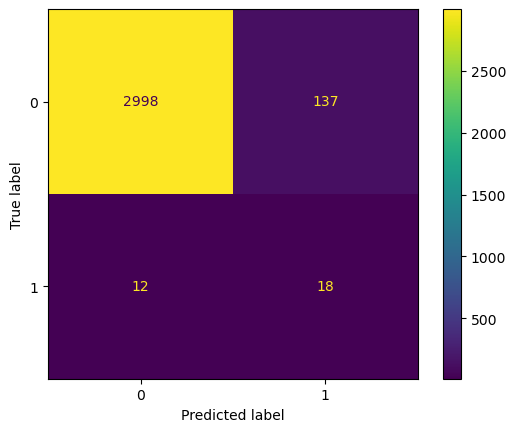

In [28]:
print("Accuracy Score = " + str(accuracy_score(y_test, y_pred_tuned)))

print("F1 Score = " + str(f1_score(y_test, y_pred_tuned)))

print("Recall Score = " + str(recall_score(y_test, y_pred_tuned)))
print("Precision Score = " + str(precision_score(y_test, y_pred_tuned)))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tuned)

## Interpretation and documented corrections

The source code trains on years **through 2015** and tests on **2016–2018**. The paper's reference to 2015–2018 testing is a wording discrepancy. Cohort membership is based on the company's median `X8` across all its records, rather than filtering each row by its own value.

The final observed year of a company labelled failed is treated as positive. An actual filing date is not present in the CSV. The figure called “information gain” for the later historical models is based on LightGBM's default split-count importance; the revised workflow explicitly uses gain importance.

The original AUC calculation uses predicted classes; the extension computes ROC AUC from prediction scores. The optional tree plot that previously failed because Graphviz was unavailable is omitted here.
